# Telco Customer Churn: Exploratory Data Analysis

A short look at the data to inform the preprocessing and modelling choices. Every finding below ties back to a decision in `churn/features.py` or `churn/train.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "churn").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn import config
from churn.data import load_raw

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)

df = load_raw()
df.shape

(7043, 21)

## 1. Structure and data types

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.dtypes.value_counts()

str        18
int64       2
float64     1
Name: count, dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as **text**, even though it is a continuous amount. The next section checks why.

## 2. Data quality

In [5]:
print("Explicit nulls:          ", int(df.isna().sum().sum()))
print("Duplicate customerIDs:   ", df[config.ID_COLUMN].duplicated().sum())
print("Duplicate profiles (excl. ID):", df.drop(columns=config.ID_COLUMN).duplicated().sum())

total_charges = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank = total_charges.isna()
print("TotalCharges that fail numeric parsing:", blank.sum())
df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Explicit nulls:           0
Duplicate customerIDs:    0
Duplicate profiles (excl. ID): 22
TotalCharges that fail numeric parsing: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


- There are no explicit nulls, but **11 `TotalCharges` values are a blank space `" "`**, which is why pandas reads the column as text.
- **Every blank row has `tenure == 0`**: these are brand-new customers who have not been billed yet. The faithful fill is `tenure × MonthlyCharges = 0`, not the column median (about 1,400), which would invent a billing history. This happens inside the pipeline (`clean_numeric`), so the API applies the same rule.
- 22 rows share an identical profile under different `customerID`s. They are distinct customers with common plans, not data errors, so they are kept.

## 3. Target: class imbalance

,count,share
Churn,,
No,5174,0.735
Yes,1869,0.265


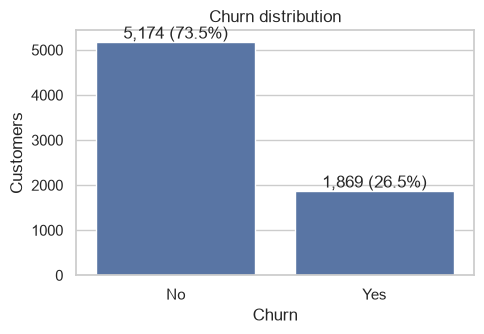

In [6]:
counts = df[config.TARGET].value_counts()
rate = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, (n, r) in enumerate(zip(counts.values, rate.values)):
    ax.text(i, n, f"{n:,} ({r:.1%})", ha="center", va="bottom")
ax.set(title="Churn distribution", xlabel="Churn", ylabel="Customers")
plt.tight_layout()
pd.DataFrame({"count": counts, "share": rate.round(3)})

**26.5% churn vs 73.5% retained: the classes are imbalanced (about 2.8 : 1).**

- A model that always predicts "No" scores **73.5% accuracy** while catching zero churners, so accuracy is a misleading metric here. We evaluate with ROC-AUC, PR-AUC, F1, precision and recall instead.
- The pipeline handles the imbalance with **class weights** (`class_weight="balanced"` / `scale_pos_weight`), a **stratified** train/test split and stratified CV folds, and a **decision threshold tuned** on cross-validated predictions rather than a fixed 0.5.

## 4. Numeric features

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1683.6
Yes,10.0,79.6,703.6


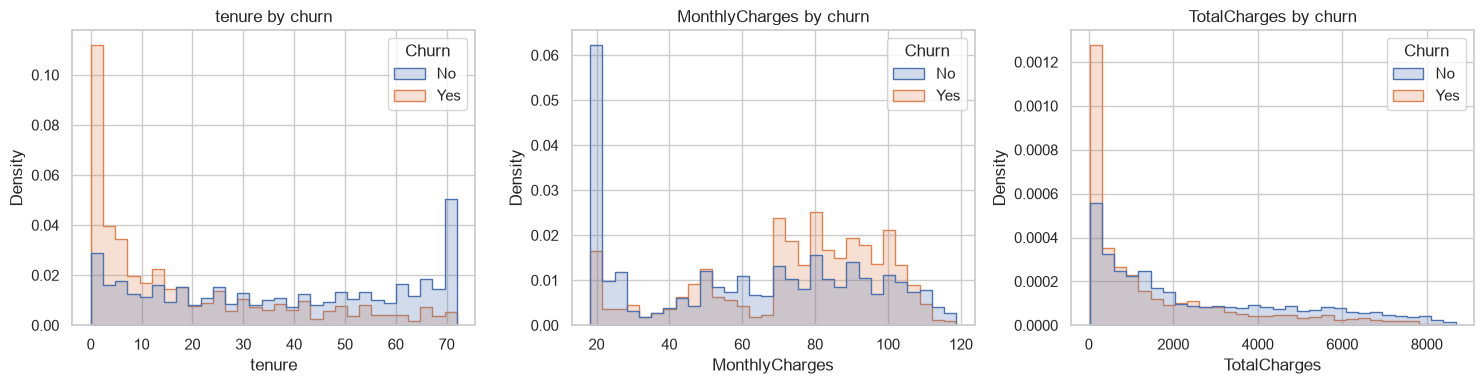

In [7]:
numeric = ["tenure", "MonthlyCharges", "TotalCharges"]
plot_df = df.assign(TotalCharges=total_charges)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric):
    sns.histplot(plot_df, x=col, hue=config.TARGET, stat="density", common_norm=False,
                 element="step", bins=30, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()

plot_df.groupby(config.TARGET)[numeric].median().round(1)

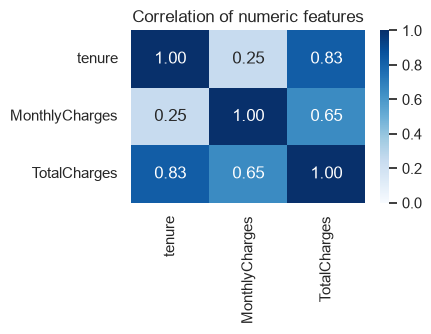

In [8]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.heatmap(plot_df[numeric].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Correlation of numeric features")
plt.tight_layout()

- **Tenure is the strongest numeric signal**: churners have a median tenure of 10 months vs 38 for retained customers. Churn is front-loaded: 47% of customers in their first year leave, vs about 10% after four years.
- **Churners pay more per month** (median about \$80 vs \$64), consistent with the fiber-optic finding below.
- `TotalCharges` is largely `tenure × MonthlyCharges` (correlation 0.83 with tenure). The collinearity is harmless for tree models and handled by L2 regularization in logistic regression, so no feature is dropped.
- The features are on very different scales (tenure up to 72, TotalCharges up to about 8,700), so numeric features are **standardized** for the linear baseline.

## 5. Categorical features: churn rate by category

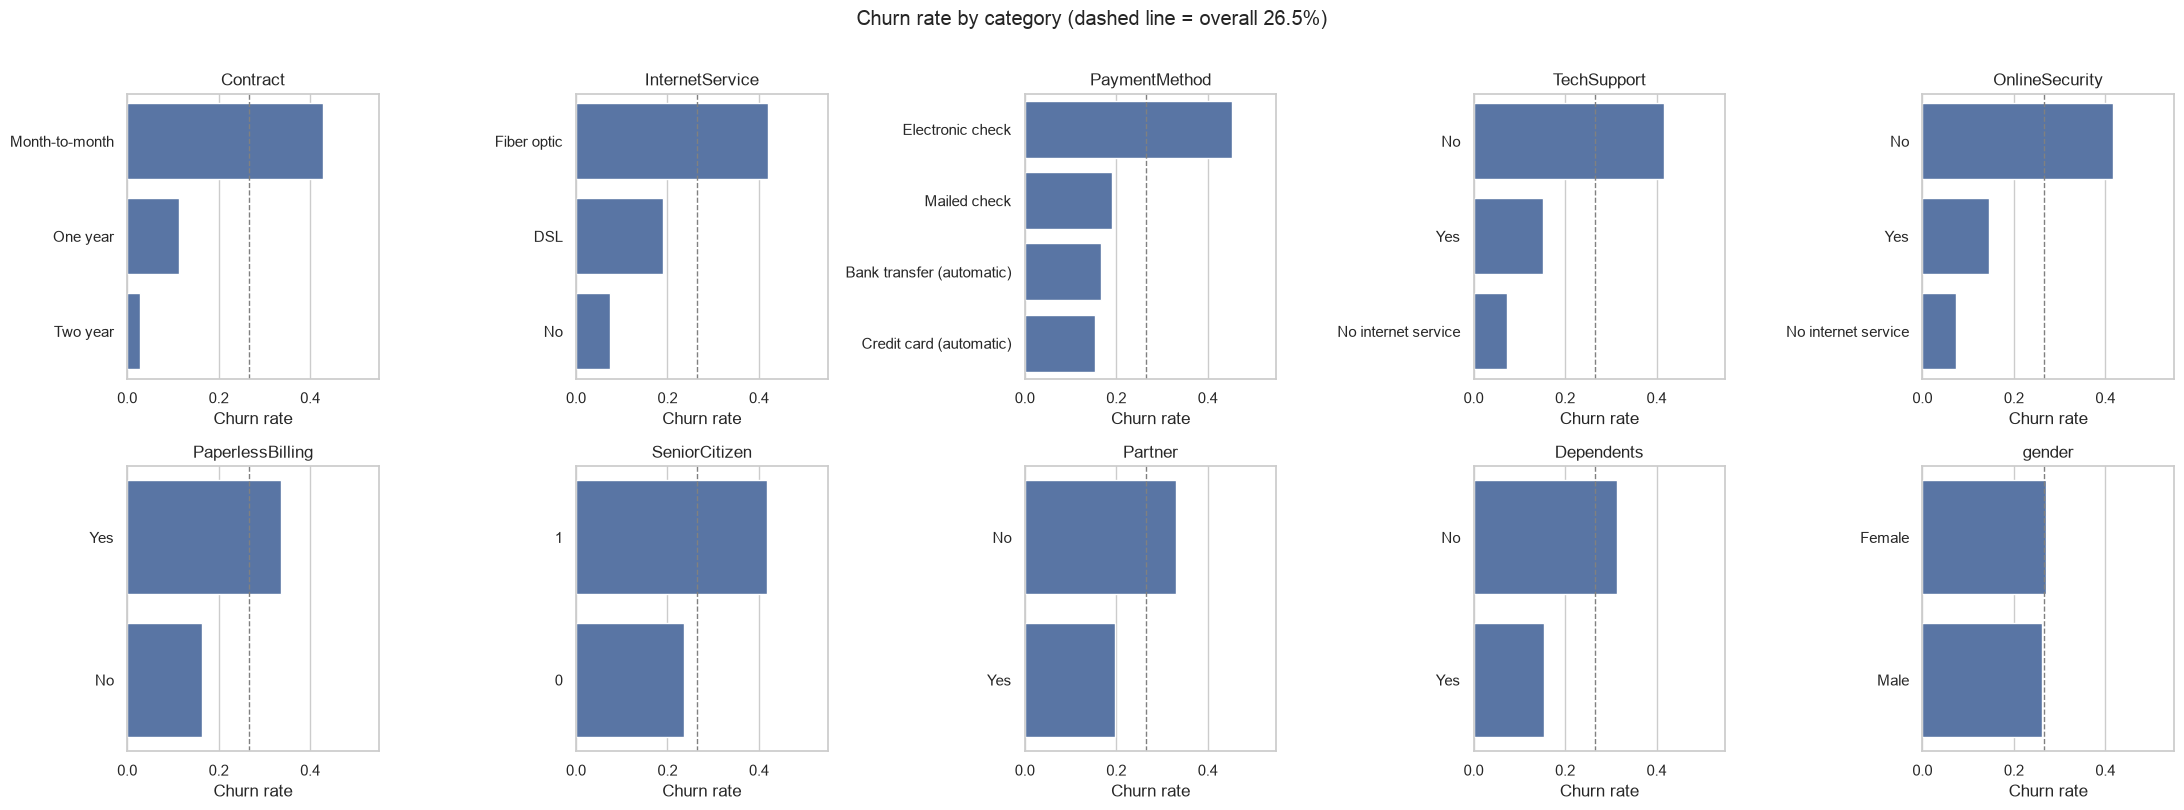

In [9]:
features = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner",
            "Dependents", "gender"]
churn_flag = (df[config.TARGET] == config.POSITIVE_LABEL).astype(int)
overall = churn_flag.mean()

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.flat, features):
    rates = churn_flag.groupby(df[col]).mean().sort_values(ascending=False)
    sns.barplot(x=rates.values, y=rates.index.astype(str), ax=ax, orient="h")
    ax.axvline(overall, color="grey", linestyle="--", linewidth=1)
    ax.set(title=col, xlabel="Churn rate", ylabel="", xlim=(0, 0.55))
plt.suptitle(f"Churn rate by category (dashed line = overall {overall:.1%})", y=1.01)
plt.tight_layout()

In [10]:
df[config.CATEGORICAL_FEATURES].nunique().sort_values(ascending=False).to_frame("unique_values")

,unique_values
PaymentMethod,4
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3
DeviceProtection,3
TechSupport,3
StreamingTV,3
StreamingMovies,3
Contract,3


- **Contract** is the dominant driver: month-to-month customers churn at 43%, two-year customers at 3%.
- **Fiber optic** (42%) and **electronic check** payment (45%) customers churn far above the average.
- Customers **without tech support or online security** churn at about 42%, vs about 15% with them.
- Senior citizens, customers without a partner or dependents, and paperless billing customers churn more. **Gender has no signal** (26.9% vs 26.2%).
- All categoricals have low cardinality (at most 4 levels), so **one-hot encoding** is appropriate and cheap (45 features in total). `handle_unknown="ignore"` keeps the API robust to unseen categories.
- The "No internet service" / "No phone service" levels repeat information from `InternetService` / `PhoneService`. That is redundant but harmless, so the raw categories are kept for simplicity.

## 6. Summary: how EDA shapes the pipeline

| Finding | Decision |
|---|---|
| `TotalCharges` stored as text, 11 blanks, all at tenure 0 | Coerce to numeric and fill with `tenure × MonthlyCharges` (= 0) **inside the pipeline**, so training and the API share one code path |
| `customerID` is a unique identifier | Dropped from features |
| 26.5% positive class | Stratified split and CV, class weights, tuned threshold; report ROC-AUC, PR-AUC, F1 rather than accuracy |
| Numeric features on very different scales | `StandardScaler` (fitted on training folds only) |
| Low-cardinality categoricals | `OneHotEncoder(handle_unknown="ignore")` |
| Strong signals: contract, tenure, internet type, payment method, support add-ons | Expect both a linear baseline and tree ensembles to do well; compare on cross-validation |
| All imputation, scaling and encoding is fitted | Done in a `ColumnTransformer` within the model `Pipeline`, fitted only on training data, to **prevent leakage** |